# Разведочный анализ данных (Эмоциональное состояние российского общества)
Датасет ВЦИОМ содержит результаты опроса 1606 респондентов. В наборе данных представлено 25 столбцов, в которых содержится информация об эмоциональном состоянии участников опроса, их возрасте, поле, образовании, материальном положении и профессиональной деятельности.

Перед началом анализа была проведена предварительная обработка данных с помощью LLM.
В исходном файле ответы на вопросы были представлены числовыми кодами, поэтому для удобства дальнейшей работы они были заменены на текстовые значения в соответствии с расшифровкой, предоставленной ВЦИОМ. Например, в столбце с полом значения 1 и 2 были заменены на «Мужчина» и «Женщина». Также были переименованы столбцы, чтобы их названия стали более понятными. При этом числовые показатели, такие как возраст и вес опроса, остались без изменений. После обработки датасет был сохранён в формате CSV для дальнейшего исследовательского анализа данных.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем CSV
try:
    df = pd.read_csv("База_эмоций_русские_названия.csv")
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))

print("Размер таблицы:", df.shape)
print("Количество респондентов:", len(df))
print("Столбцы:", df.columns.tolist())

display(df.head())

Saving Эмоции_Русские_Названия.csv to Эмоции_Русские_Названия.csv
Размер таблицы: (1606, 25)
Количество респондентов: 1606
Столбцы: ['ID респондента', 'Пол', 'Возраст', 'Федеральный округ', 'Тип населённого пункта', 'Радость', 'Воодушевление', 'Доброжелательность', 'Надежда', 'Уверенность', 'Спокойствие', 'Страх', 'Тревога', 'Растерянность', 'Грусть', 'Злость', 'Раздражение', 'Просмотр телевизора', 'Использование интернета', 'Образование', 'Материальное положение семьи', 'Основное занятие', 'Тип организации', 'Сфера деятельности организации', 'Вес опроса']


,ID респондента,Пол,Возраст,Федеральный округ,Тип населённого пункта,Радость,Воодушевление,Доброжелательность,Надежда,Уверенность,...,Злость,Раздражение,Просмотр телевизора,Использование интернета,Образование,Материальное положение семьи,Основное занятие,Тип организации,Сфера деятельности организации,Вес опроса
0,0af5ec4e674ced50,Мужчина,24,Южный федеральный округ,Село,Скорее да,Скорее да,Скорее да,Скорее да,Скорее да,...,Скорее нет,Скорее нет,Не смотрю,Несколько раз в неделю,Среднее профессиональное образование,Среднее,Наёмный работник,"Правоохранительные органы, ВС, МЧС",Правоохранительные органы и военная служба,1.573387
1,0af5f4744d4ce895,Мужчина,18,Южный федеральный округ,Село,Скорее да,Скорее да,Скорее да,Скорее да,Скорее да,...,Скорее нет,Скорее нет,Не смотрю,Провожу в интернете более четырех часов ежедневно,Основное общее образование,Среднее,"Работающий учащийся, студент",Коммерческая организация,Торговля и недвижимость,1.573387
2,0af5c87b9c8ce408,Мужчина,18,Приволжский федеральный округ,Село,Скорее да,Скорее нет,Скорее да,Скорее да,Скорее да,...,Скорее нет,Скорее нет,Ежедневно менее четырех часов в день,Провожу в интернете более четырех часов ежедневно,Среднее профессиональное образование,Хорошее,Наёмный работник,Коммерческая организация,Промышленность и производство,2.236462
3,0af5aa7f5e4ce95e,Мужчина,19,Уральский федеральный округ,Село,Скорее да,Затрудняюсь ответить,Скорее да,Скорее нет,Скорее да,...,Скорее нет,Скорее нет,Не смотрю,Провожу в интернете более четырех часов ежедневно,Основное общее образование,Среднее,"Работающий учащийся, студент",Коммерческая организация,Бытовые и сервисные услуги,1.741430
4,0af5ba0342cce738,Мужчина,19,Сибирский федеральный округ,Село,Скорее да,Скорее нет,Скорее да,Скорее да,Скорее да,...,Скорее нет,Скорее нет,Несколько раз в неделю,Ежедневно менее четырёх часов в день,Среднее профессиональное образование,Среднее,Самозанятый,NaN,Промышленность и производство,1.833281


В датасете имеется 25 столбцов.
1. ID респондента
2. Пол
3. Возраст
4. Федеральный округ
5. Тип населённого пункта
6. Радость
7. Воодушевление
8. Доброжелательность
9. Надежда
10. Уверенность
11. Спокойствие
12. Страх
13. Тревога
14. Растерянность
15. Грусть
16. Злость
17. Раздражение
18. Просмотр телевизора
19. Использование интернета
20. Образование
21. Материальное положение семьи
22. Основное занятие
23. Тип организации
24. Сфера деятельности организации
25. Вес опроса (Вес опроса это числовой коэффициент, который показывает, насколько сильно ответ конкретного респондента должен учитываться при расчёте общей статистики. Он нужен для того, чтобы результаты опроса лучше отражали население России.)

Из них 12 столбцов описывают эмоциональное состояние, 11 содержат социально-демографические характеристики и сведения о привычках и занятости, а ещё 2 представляют собой идентификатор респондента и вес опроса.

In [2]:
# Общая информация о датасете
df.info()

# Количество пропусков в каждом столбце
print("\nПропущенные значения:")
display(df.isnull().sum().to_frame(name="Количество пропусков"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1606 entries, 0 to 1605
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ID респондента                  1606 non-null   object 
 1   Пол                             1606 non-null   object 
 2   Возраст                         1606 non-null   int64  
 3   Федеральный округ               1606 non-null   object 
 4   Тип населённого пункта          1606 non-null   object 
 5   Радость                         1606 non-null   object 
 6   Воодушевление                   1606 non-null   object 
 7   Доброжелательность              1606 non-null   object 
 8   Надежда                         1606 non-null   object 
 9   Уверенность                     1606 non-null   object 
 10  Спокойствие                     1606 non-null   object 
 11  Страх                           1606 non-null   object 
 12  Тревога                         16

,Количество пропусков
ID респондента,0
Пол,0
Возраст,0
Федеральный округ,0
Тип населённого пункта,0
Радость,0
Воодушевление,0
Доброжелательность,0
Надежда,0
Уверенность,0


Пропуски наблюдаются только в двух столбцах: "тип организации" и "сфера деятельности". Причина: у пенсионеров, безработных и студентов без работы нет организации, эти строки удалять нельзя.

In [3]:
import numpy as np
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

sns.set_theme(style='white', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.autolayout'] = True
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titlepad'] = 14
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

C_GOOD = '#2a9d8f'
C_BAD  = '#e76f51'
C_MID  = '#e9c46a'
C_NEUT = '#8d99ae'

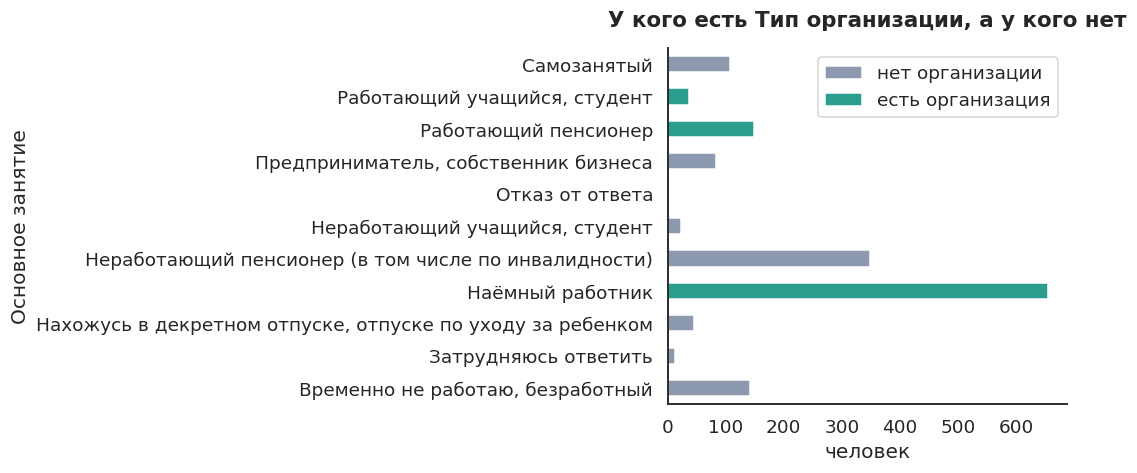

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sub = df.assign(filled=df['Тип организации'].notna())
piv = sub.groupby(['Основное занятие', 'filled']).size().unstack(fill_value=0)
piv.plot(kind='barh', stacked=True, ax=ax, color=[C_NEUT, C_GOOD])
ax.set_title('У кого есть Тип организации, а у кого нет')
ax.set_xlabel('человек')
ax.legend(['нет организации', 'есть организация'], title='')
plt.show()

Зеленое - организация - есть только только у работающих. Серое - нет организации - у пенсионеров, безработных, студентов

## Проверка качества ответов

Бывает, что человек отвечает "cкорее да" на все 12 эмоций подряд, чтобы быстрее закончить. Проверка, много ли таких респондентов:

In [5]:
emotions = ['Радость','Воодушевление','Доброжелательность','Надежда','Уверенность','Спокойствие',
            'Страх','Тревога','Растерянность','Грусть','Злость','Раздражение']
pos = emotions[:6]
neg = emotions[6:]

df['n_variants'] = df[emotions].nunique(axis=1)
df['n_variants'].value_counts().sort_index()

,count
n_variants,
1,8
2,1429
3,169


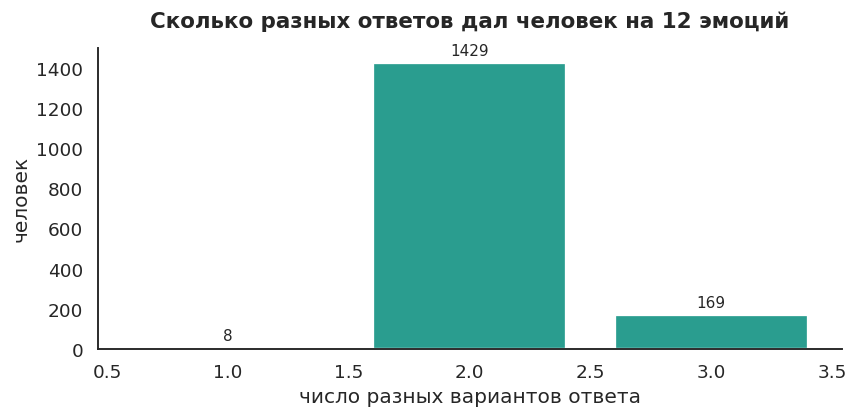

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
counts = df['n_variants'].value_counts().sort_index()
bars = ax.bar(counts.index, counts.values, color=C_GOOD, edgecolor='white', linewidth=1.5)
ax.bar_label(bars, padding=3, fontsize=10)
ax.set_title('Сколько разных ответов дал человек на 12 эмоций')
ax.set_xlabel('число разных вариантов ответа')
ax.set_ylabel('человек')
plt.show()

Большинство людей дают 3-5 разных ответов, они различают эмоции. Ответов с одним вариантом немного

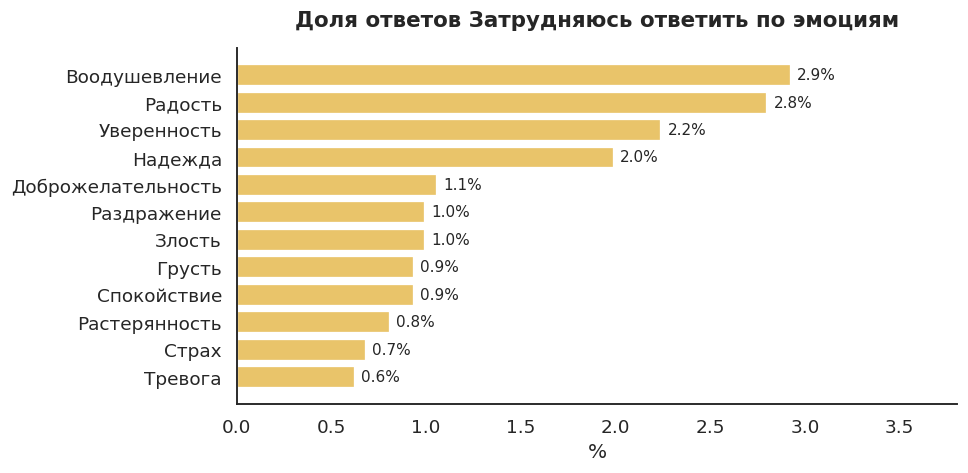

In [7]:
dk = df[emotions].apply(lambda s: (s == 'Затрудняюсь ответить').mean()).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(dk.index, dk.values * 100, color=C_MID, edgecolor='white', linewidth=1.5)
ax.bar_label(bars, fmt='%.1f%%', padding=4, fontsize=10)
ax.set_title('Доля ответов Затрудняюсь ответить по эмоциям')
ax.set_xlabel('%')
ax.set_xlim(0, dk.max() * 130)
plt.show()

Чаще всего люди сомневаются в особенно ярких эмоциях, например "воодушевление","радость"

## Ответы после взвешивания

ВЦИОМ даёт каждому человеку вес. Это число показывает, насколько сильно его ответ должен учитываться. Нужно, чтобы выборка лучше отражала всё население России. В опросе, например, больше молодых мужчин, чем в стране

In [25]:
df['w_norm'] = df['Вес опроса'] / df['Вес опроса'].sum() * len(df)
print('Сумма весов:', round(df['Вес опроса'].sum(), 1))
print('Сумма нормированных:', round(df['w_norm'].sum(), 1), '| человек:', len(df))

w = df['Вес опроса']
ess = w.sum()**2 / (w**2).sum()
print(f'После взвешивания остаётся примерно {ess:.0f} человек из {len(df)}')

Сумма весов: 1600.0
Сумма нормированных: 1606.0 | человек: 1606
После взвешивания остаётся примерно 1321 человек из 1606


После взвешивания выборка сжимается примерно до 1300-1400 человек

In [27]:
df['age_group'] = pd.cut(df['Возраст'],
                         bins=[17, 24, 34, 44, 59, 200],
                         labels=['18-24','25-34','35-44','45-59','60+'])

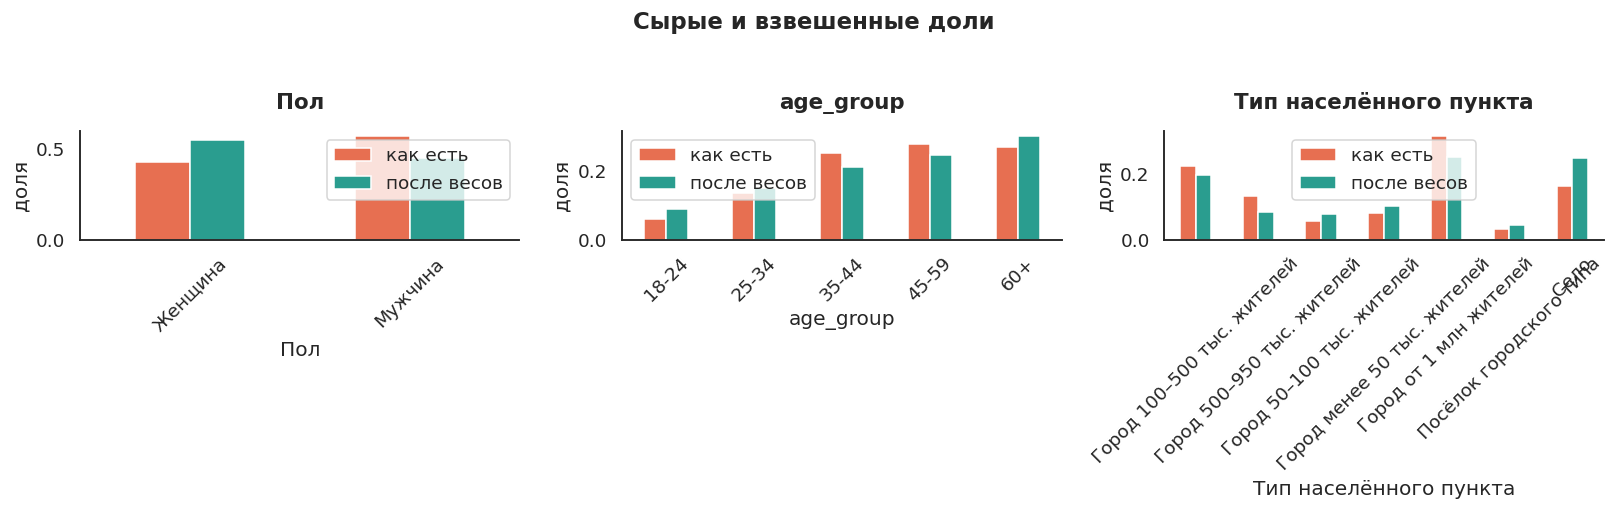

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col in zip(axes, ['Пол', 'age_group', 'Тип населённого пункта']):
    raw = df[col].value_counts(normalize=True).sort_index()
    wtd = df.groupby(col)['w_norm'].sum() / df['w_norm'].sum()
    pd.DataFrame({'как есть': raw, 'после весов': wtd}).plot(
        kind='bar', ax=ax, color=[C_BAD, C_GOOD], edgecolor='white')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylabel('доля')

plt.suptitle('Сырые и взвешенные доли', y=1.03, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

Оранжевые столбцы это как есть, с перекосом в молодых мужчин. Зелёные столбцы это после весов, ближе к реальному населению. Видно, что веса немного выравнивают картину

## Демография опроса


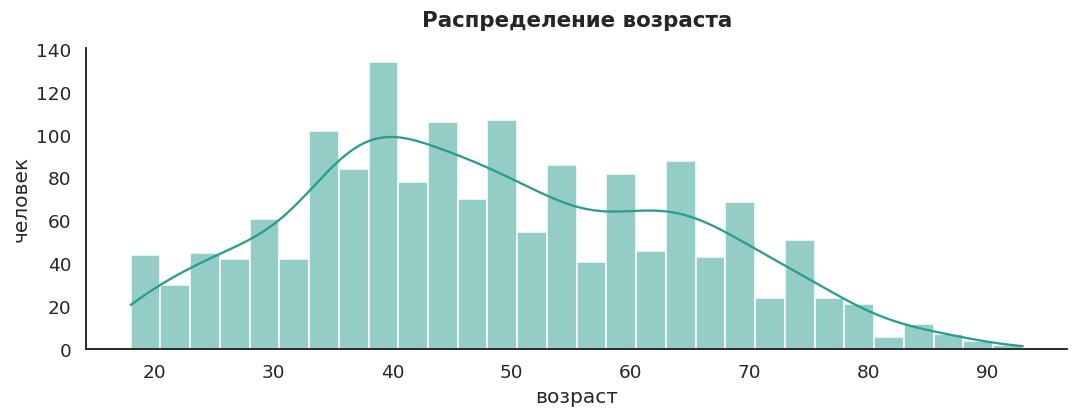

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df['Возраст'], bins=30, kde=True, color=C_GOOD, ax=ax)
ax.set_title('Распределение возраста')
ax.set_xlabel('возраст')
ax.set_ylabel('человек')
plt.show()

В выборке много молодых, 18-24, и много пожилых, 60+. Середина 45-59 проваливается

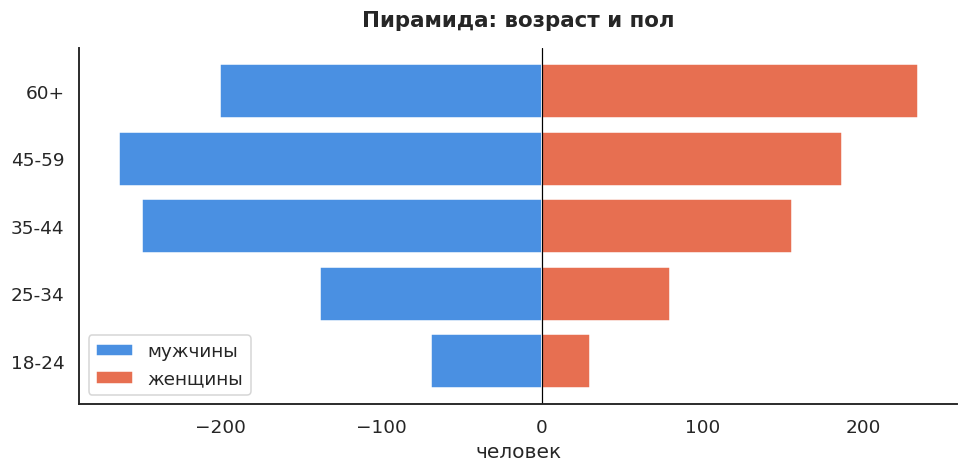

In [12]:
pyr = df.groupby(['age_group', 'Пол']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(pyr.index, -pyr['Мужчина'], color='#4a90e2', label='мужчины')
ax.barh(pyr.index,  pyr['Женщина'], color=C_BAD, label='женщины')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Пирамида: возраст и пол')
ax.set_xlabel('человек')
ax.legend()
plt.show()

Молодых мужчин в выборке заметно больше, чем молодых женщин. У пожилых наоборот, женщин больше

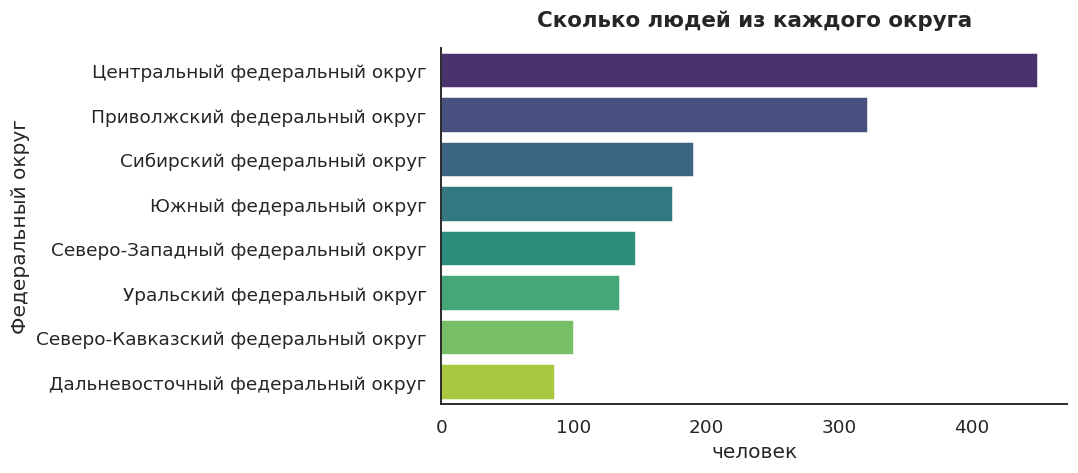

In [13]:
order = df['Федеральный округ'].value_counts().index
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.countplot(data=df, y='Федеральный округ', order=order, palette='viridis', ax=ax)
ax.set_title('Сколько людей из каждого округа')
ax.set_xlabel('человек')
plt.show()

Респонденты есть из всех 8 округов. Больше всего из Центрального и Приволжского. Это логично, так как это самые густо населенные округа

## Анализ эмоций


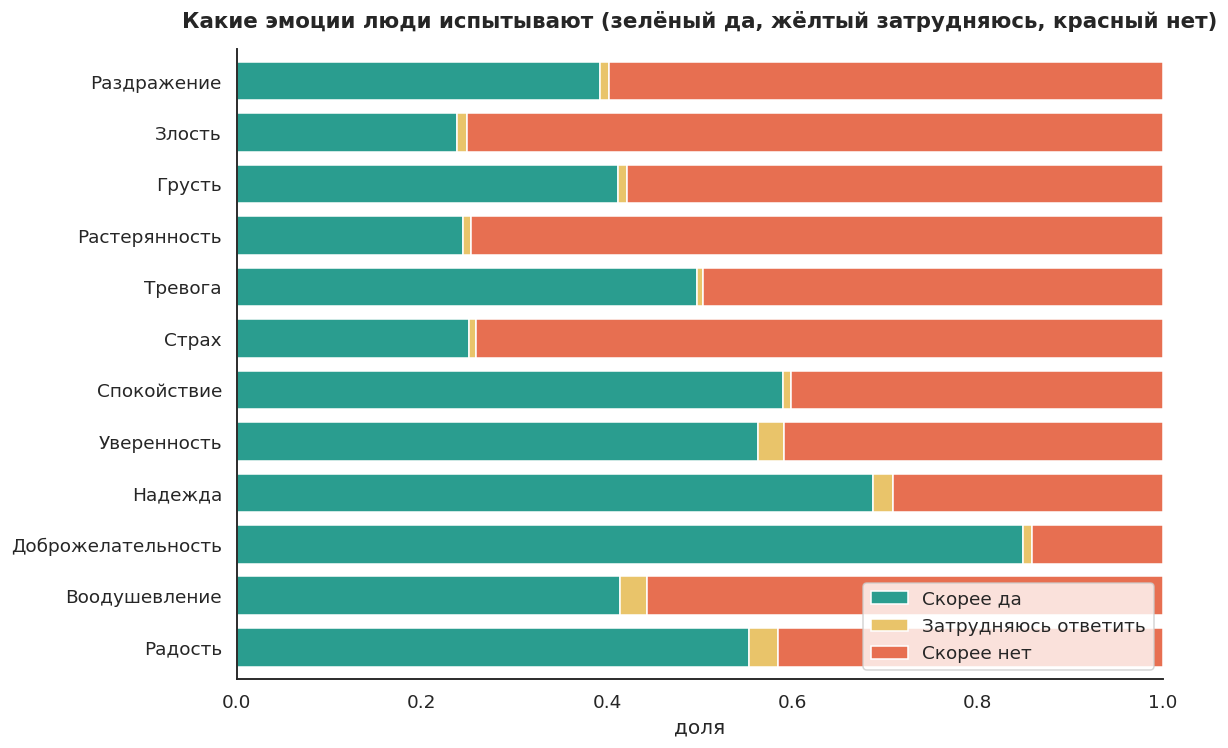

In [14]:
dist = {e: df.groupby(e)['w_norm'].sum() / df['w_norm'].sum() for e in emotions}
dist_df = pd.DataFrame(dist).T
cols_order = [c for c in ['Скорее да', 'Затрудняюсь ответить', 'Скорее нет'] if c in dist_df.columns]
dist_df = dist_df[cols_order]

fig, ax = plt.subplots(figsize=(11, 7))
dist_df.plot(kind='barh', stacked=True, ax=ax, color=[C_GOOD, C_MID, C_BAD], width=0.75)
ax.set_title('Какие эмоции люди испытывают (зелёный да, жёлтый затрудняюсь, красный нет)')
ax.set_xlabel('доля')
ax.legend(title='', loc='lower right')
ax.set_xlim(0, 1)
plt.show()

Зеленого, то есть положительных эмоций, в среднем больше, чем красного. Особенно много "да" у "радости", "доброжелательности", "надежды", "уверенности". Негативные эмоции "страх" и "тревогу" люди отмечают реже. Значит, в целом фон более позитивный

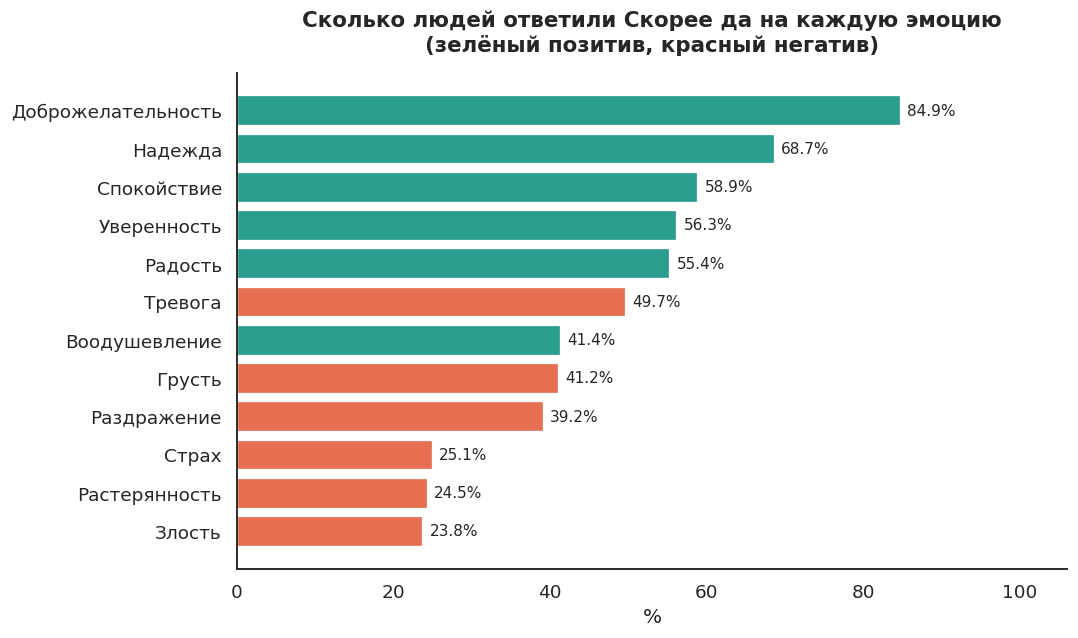

In [15]:
yes = pd.Series({e: df.loc[df[e]=='Скорее да', 'w_norm'].sum() / df['w_norm'].sum() for e in emotions})
yes = yes.sort_values()

colors = [C_GOOD if e in pos else C_BAD for e in yes.index]
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(yes.index, yes.values * 100, color=colors, edgecolor='white', linewidth=1.5)
ax.bar_label(bars, fmt='%.1f%%', padding=4, fontsize=10)
ax.set_title('Сколько людей ответили Скорее да на каждую эмоцию\n(зелёный позитив, красный негатив)')
ax.set_xlabel('%')
ax.set_xlim(0, yes.max() * 125)
plt.show()

Вывод для проекта: самые частые эмоции это "радость", "доброжелательность", "надежда". Их можно использовать как якоря в диалоге. Самые редкие это "страх" и "тревога", но они важнее всего для выявления диагноза

### Взаимосвязь между эмоциями

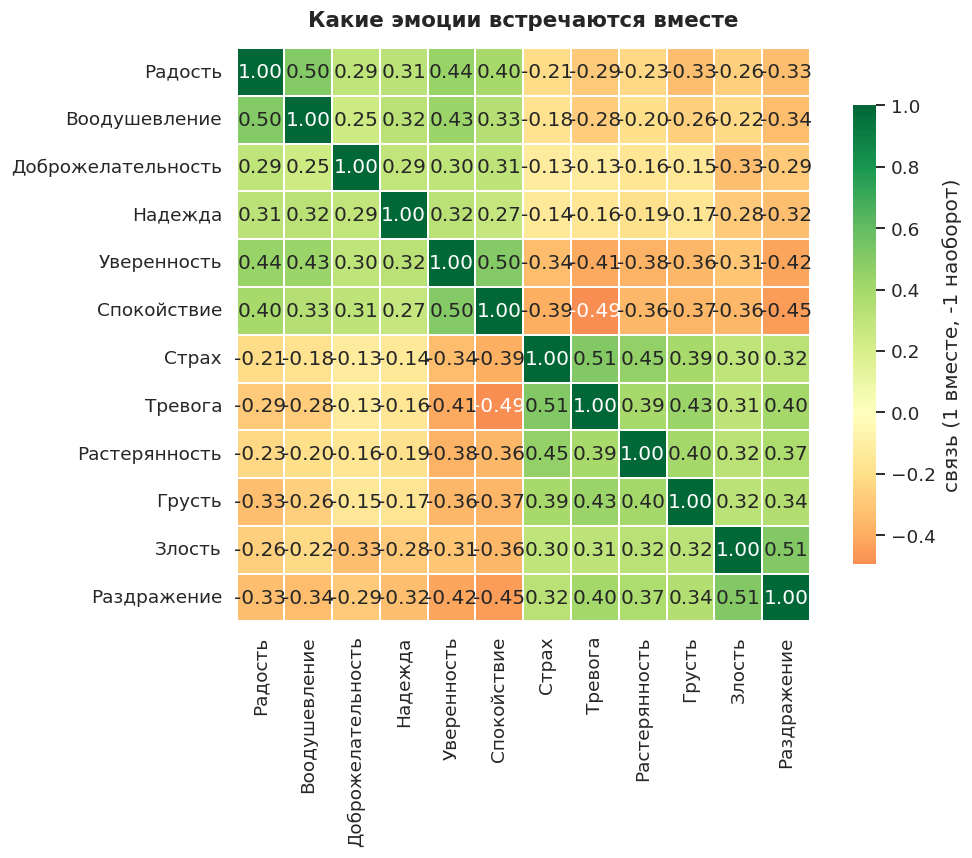

In [16]:
code_map = {'Скорее нет': 0, 'Затрудняюсь ответить': 1, 'Скорее да': 2}
enc = df[emotions].apply(lambda s: s.map(code_map))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(enc.corr(method='spearman'), annot=True, fmt='.2f',
            cmap='RdYlGn', center=0, square=True,
            linewidths=1, linecolor='white',
            cbar_kws={'shrink': .8, 'label': 'связь (1 вместе, -1 наоборот)'})
ax.set_title('Какие эмоции встречаются вместе')
plt.show()

Зеленые квадраты в левом верхнем углу означают, что позитивные эмоции связаны друг с другом. Зеленые в правом нижнем означают, что негативные тоже связаны. Связь между позитивом и негативом отрицательная

Вывод для проекта: можно не спрашивать про все 12 эмоций, а смотреть на два показателя, общий позитивный или негативный фон. Это будет проще и для пациента, и для бота

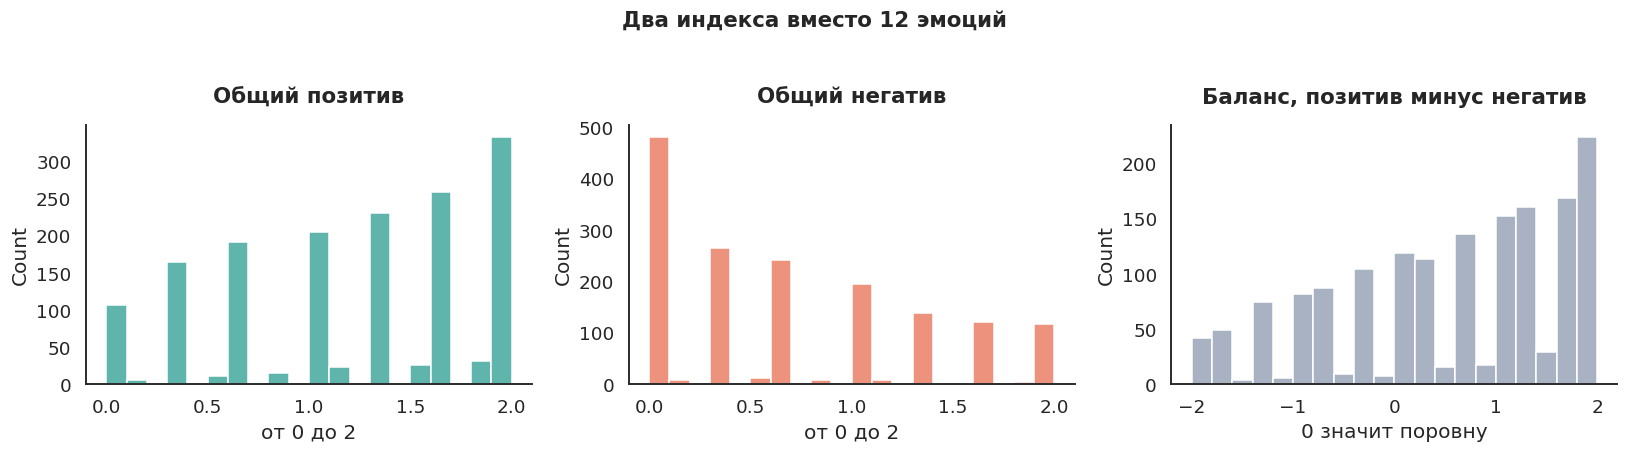

In [17]:
df['pos_index'] = enc[pos].mean(axis=1)
df['neg_index'] = enc[neg].mean(axis=1)
df['balance']   = df['pos_index'] - df['neg_index']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['pos_index'], bins=20, color=C_GOOD, ax=axes[0])
axes[0].set_title('Общий позитив'); axes[0].set_xlabel('от 0 до 2')
sns.histplot(df['neg_index'], bins=20, color=C_BAD,  ax=axes[1])
axes[1].set_title('Общий негатив'); axes[1].set_xlabel('от 0 до 2')
sns.histplot(df['balance'],   bins=20, color=C_NEUT, ax=axes[2])
axes[2].set_title('Баланс, позитив минус негатив'); axes[2].set_xlabel('0 значит поровну')
plt.suptitle('Два индекса вместо 12 эмоций', y=1.03, fontsize=14, fontweight='bold')
plt.show()

У большинства респондентов баланс положительный, позитив перевешивает негатив. Но есть группа с отрицательным балансом, столбики слева от нуля. Это люди, у которых негатив сильнее. Для чата они являются приоритетной группой внимания

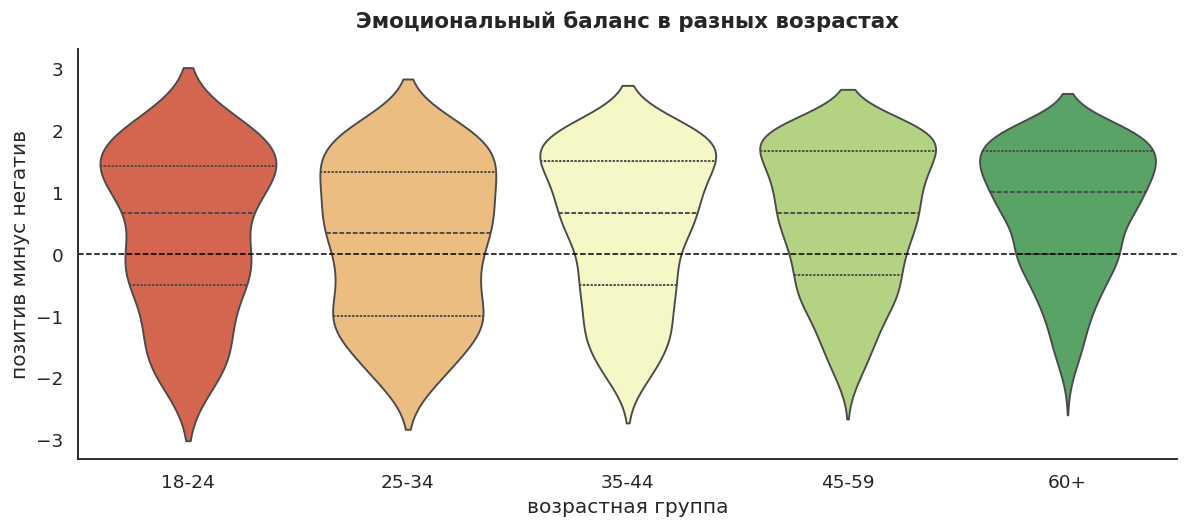

In [18]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.violinplot(data=df, x='age_group', y='balance', palette='RdYlGn', inner='quartile', ax=ax)
ax.axhline(0, color='black', ls='--', linewidth=1)
ax.set_title('Эмоциональный баланс в разных возрастах')
ax.set_xlabel('возрастная группа')
ax.set_ylabel('позитив минус негатив')
plt.show()

У молодых, 18-24, баланс самый разбросанный. Есть и очень позитивные, и очень негативные. У пожилых, 60 плюс, баланс ровнее и чаще положительный. Эмоциональному фону молодых людей чату стоит уделять больше внимания

## Шаг 6. Как эмоции зависят от других факторов

Смотрим, у кого каких эмоций больше, по возрасту, полу, достатку.

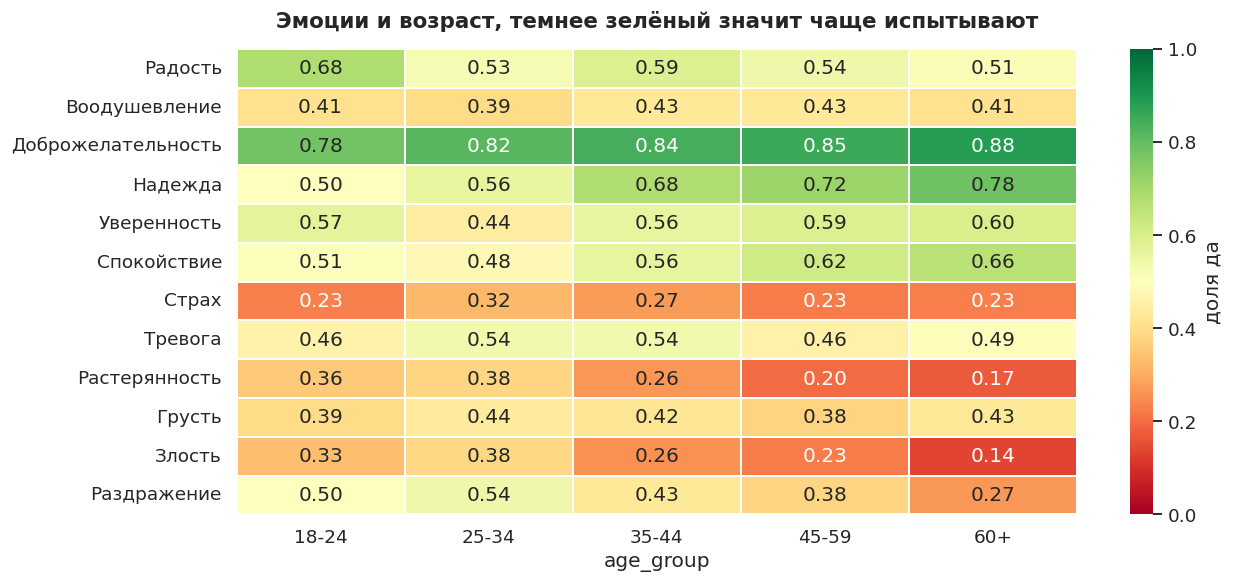

In [19]:
def share_yes(col, group):
    tmp = df.assign(yes=(df[col] == 'Скорее да'), w=df['w_norm'])
    return tmp.groupby(group).apply(lambda g: (g['yes'] * g['w']).sum() / g['w'].sum())

piv_age = pd.DataFrame({e: share_yes(e, 'age_group') for e in emotions})
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(piv_age.T, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
            linewidths=1, linecolor='white', cbar_kws={'label': 'доля да'})
ax.set_title('Эмоции и возраст, темнее зелёный значит чаще испытывают')
plt.show()

У молодых, 18-24, заметно больше тревоги, растерянности и грусти, чем у пожилых. У пожилых, 60 плюс, больше спокойствия.

Вывод для проекта: с молодыми пациентами лучше быть аккуратнее, давать больше поддержки

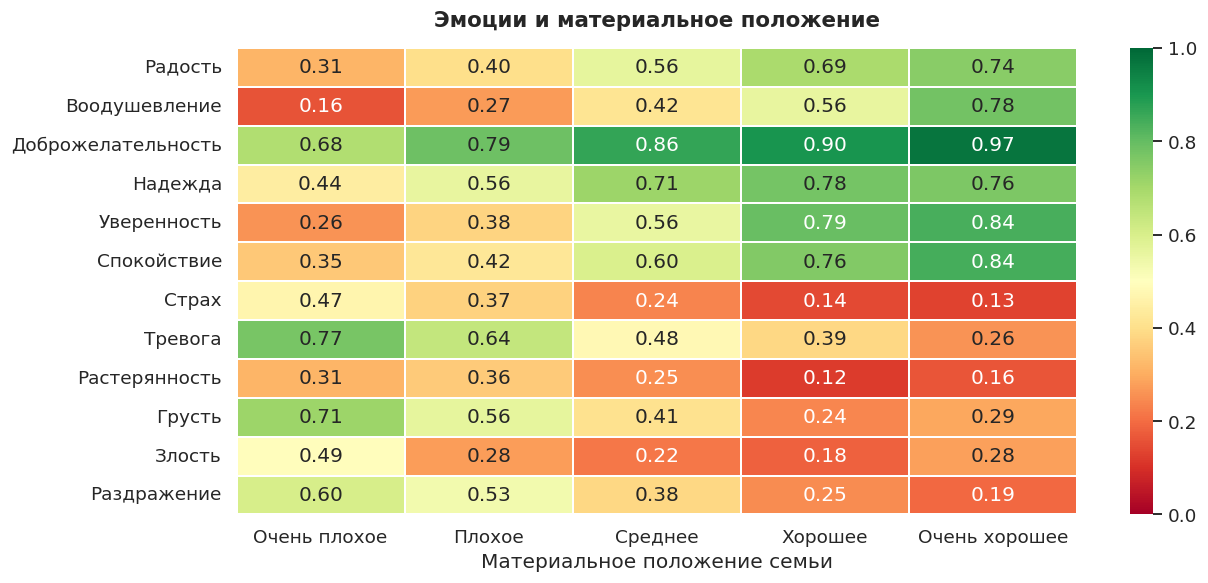

In [20]:
mp_order = ['Очень плохое', 'Плохое', 'Среднее', 'Хорошее', 'Очень хорошее']
piv_mp = pd.DataFrame({e: share_yes(e, 'Материальное положение семьи') for e in emotions})
piv_mp = piv_mp.reindex([c for c in mp_order if c in piv_mp.index])

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(piv_mp.T, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
            linewidths=1, linecolor='white')
ax.set_title('Эмоции и материальное положение')
plt.show()

У людей с плохим достатком резко больше страха, тревоги, грусти, растерянности и почти нет радости.

Вывод для проекта: пациент с низким доходом более вероятно тревожный, к нему нужен более внимательный подход

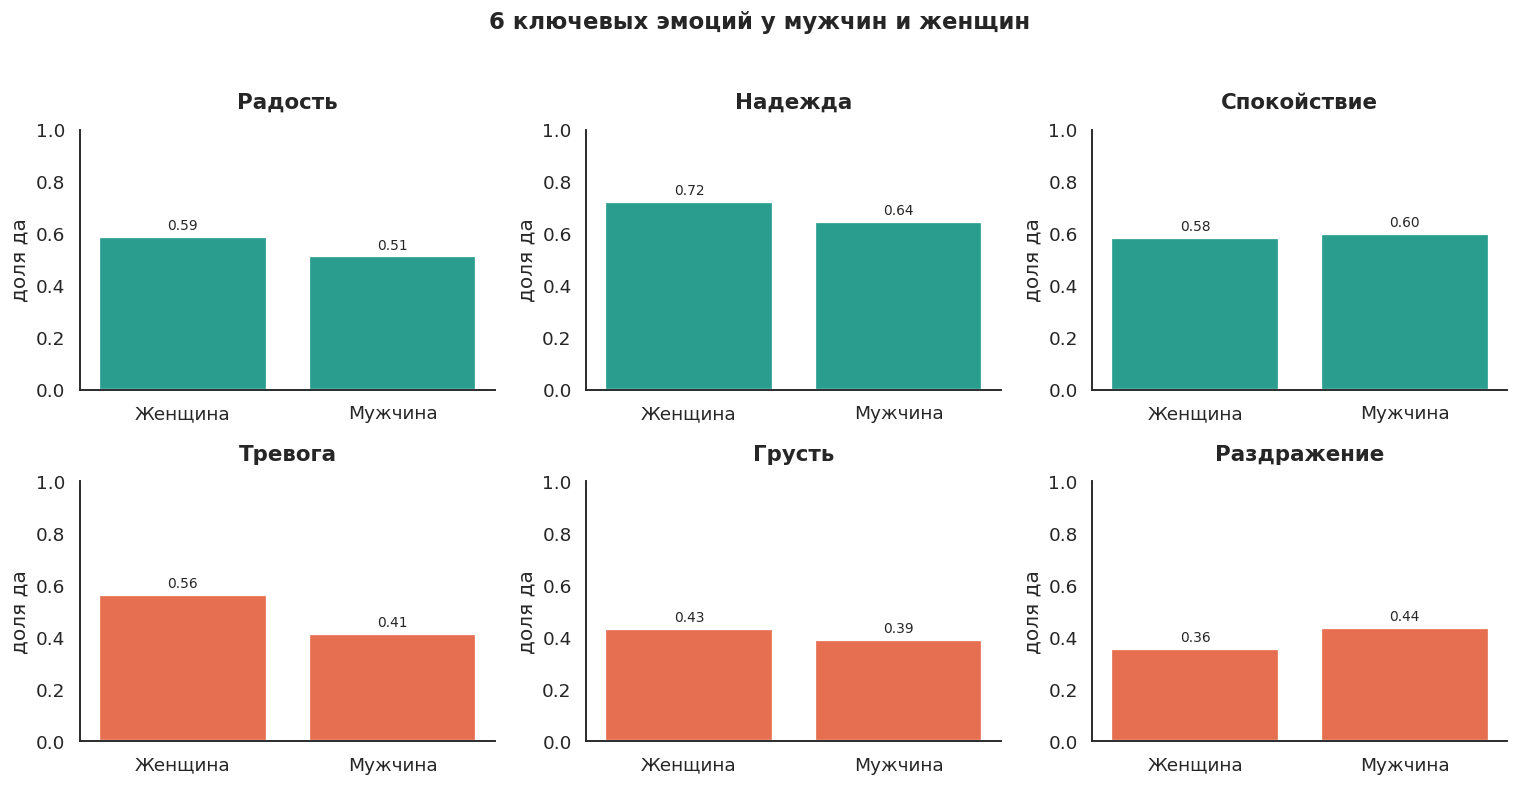

In [21]:
key = ['Радость', 'Надежда', 'Спокойствие', 'Тревога', 'Грусть', 'Раздражение']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, e in zip(axes.flat, key):
    s = share_yes(e, 'Пол')
    colors = [C_GOOD if e in pos else C_BAD] * len(s)
    bars = ax.bar(s.index, s.values, color=colors, edgecolor='white', linewidth=1.5)
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=9)
    ax.set_title(e)
    ax.set_ylim(0, 1)
    ax.set_ylabel('доля да')
plt.suptitle('6 ключевых эмоций у мужчин и женщин', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

Женщины чаще отмечают тревогу и грусть, мужчины спокойствие. Разница не огромная, но заметная. В проекте стоит учитывать, что женщины могут быть более склонны делиться тревогой

## Общая картинка, PCA и кластеры

Все 12 эмоций можно сжать в 2 общие оси, позитив и негатив, а людей разбить на несколько типов, как делает ВЦИОМ в своей методике

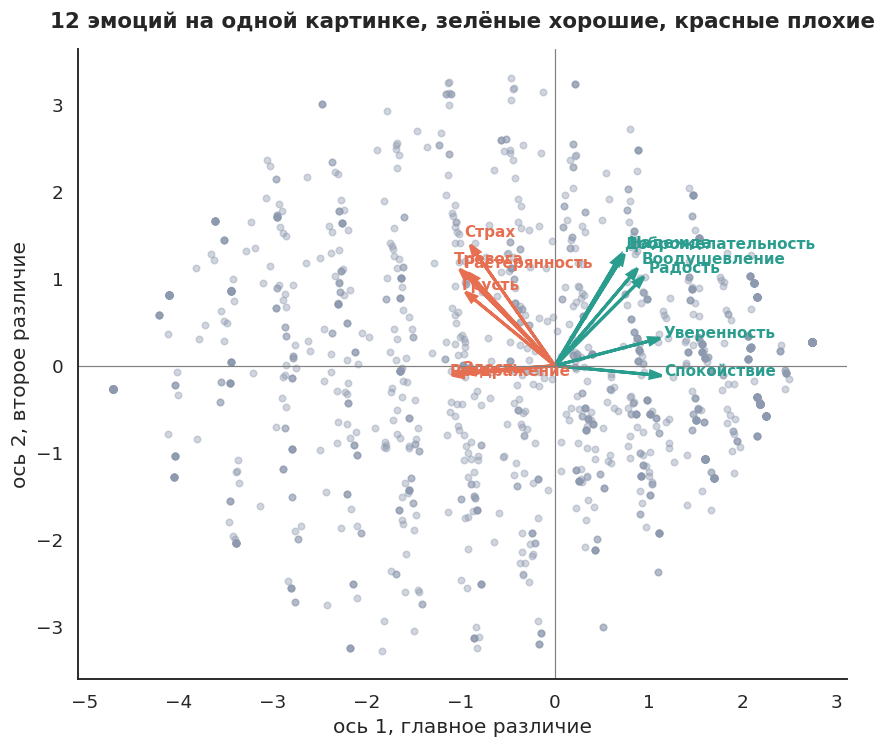

In [22]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X = StandardScaler().fit_transform(enc.fillna(enc.mean()))
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(coords[:, 0], coords[:, 1], s=18, alpha=.4, color=C_NEUT)
for i, e in enumerate(emotions):
    v = pca.components_[:2, i] * 3
    color = C_GOOD if e in pos else C_BAD
    ax.arrow(0, 0, v[0], v[1], color=color, head_width=.08, linewidth=2)
    ax.text(v[0] * 1.15, v[1] * 1.15, e, fontsize=10, fontweight='bold', color=color)
ax.set_title('12 эмоций на одной картинке, зелёные хорошие, красные плохие')
ax.set_xlabel('ось 1, главное различие'); ax.set_ylabel('ось 2, второе различие')
ax.axhline(0, color='gray', linewidth=0.8); ax.axvline(0, color='gray', linewidth=0.8)
plt.show()

Зеленые стрелки, хорошие эмоции, смотрят в одну сторону, красные, плохие, в другую. Эмоции делятся на два лагеря. В проекте можно использовать два индекса вместо 12 эмоций.

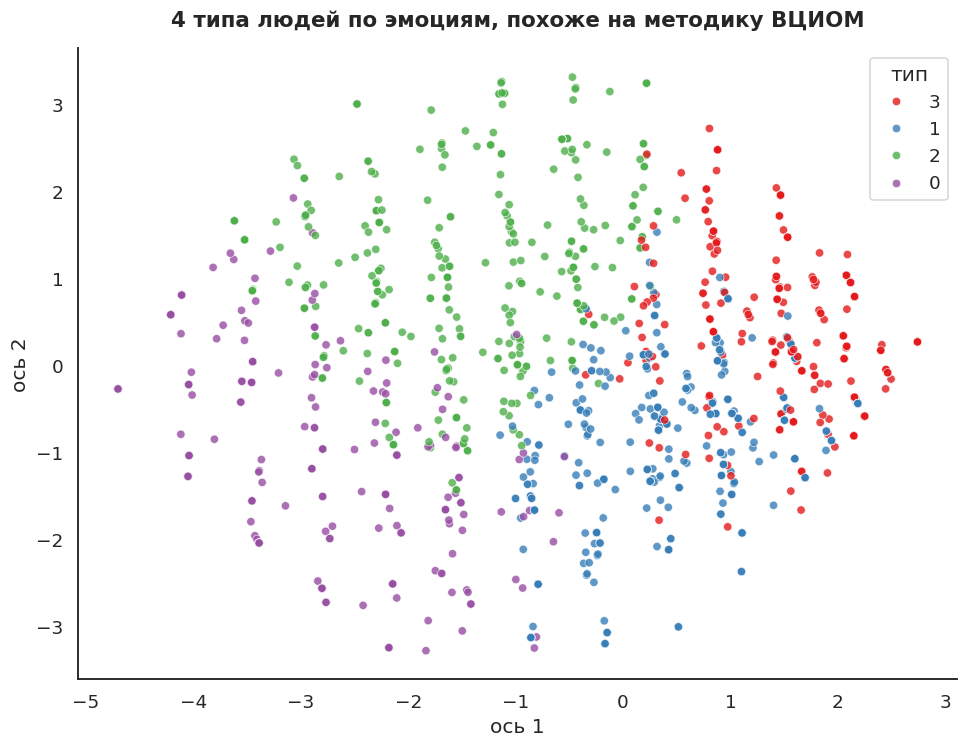

In [23]:
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X)
df['cluster'] = km.labels_

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df['cluster'].astype(str),
                palette='Set1', s=30, alpha=.8, ax=ax)
ax.set_title('4 типа людей по эмоциям, похоже на методику ВЦИОМ')
ax.set_xlabel('ось 1'); ax.set_ylabel('ось 2')
ax.legend(title='тип', bbox_to_anchor=(1, 1))
plt.show()

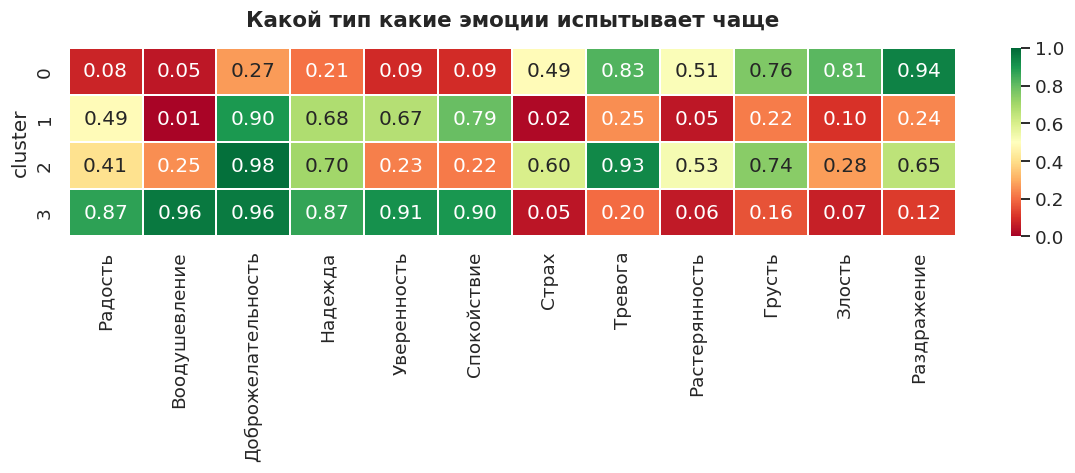

In [24]:
profile = df.groupby('cluster')[emotions].apply(lambda g: g.eq('Скорее да').mean())

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(profile, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
            linewidths=1, linecolor='white')
ax.set_title('Какой тип какие эмоции испытывает чаще')
plt.show()

Отчетливо видно 4 типа. 1) Спокойные, много позитива, мало негатива. 2) Жизнерадостные, максимум позитива. 3) Тревожные, много негатива, мало позитива. 4)Возбуждённые, высокие и позитив, и негатив одновременно.

Это совпадает с тем, как ВЦИОМ описывает свои сегменты.

Вывод для проекта: тревожных нужно выявлять первыми, они самая уязвимая группа